# Lab 04 - Data Visualization with Matplotlib

## Titanic Passenger Dataset

In this lab we use only the `train.csv` file to draw different types of charts.

In [1]:
# Import the libraries
import pandas as pd
import matplotlib.pyplot as plt

---
## Problem 1 - Load and Inspect the Dataset

First we load the data and look at the first five rows.

In [2]:
# Load the Titanic dataset
df = pd.read_csv("train.csv")

# Show the first five rows
df.head()

,PassengerId,Survived,Pclass,Name,Sex,Age,SibSp,Parch,Ticket,Fare,Cabin,Embarked
0,1,0,3,"Braund, Mr. Owen Harris",male,22.0,1,0,A/5 21171,7.2500,NaN,S
1,2,1,1,"Cumings, Mrs. John Bradley (Florence Briggs Th...",female,38.0,1,0,PC 17599,71.2833,C85,C
2,3,1,3,"Heikkinen, Miss. Laina",female,26.0,0,0,STON/O2. 3101282,7.9250,NaN,S
3,4,1,1,"Futrelle, Mrs. Jacques Heath (Lily May Peel)",female,35.0,1,0,113803,53.1000,C123,S
4,5,0,3,"Allen, Mr. William Henry",male,35.0,0,0,373450,8.0500,NaN,S


In [3]:
# Number of rows and columns
print("Rows and columns:", df.shape)

# Column names, data types and non-null counts
df.info()

Rows and columns: (891, 12)
<class 'pandas.DataFrame'>
RangeIndex: 891 entries, 0 to 890
Data columns (total 12 columns):
 #   Column       Non-Null Count  Dtype  
---  ------       --------------  -----  
 0   PassengerId  891 non-null    int64  
 1   Survived     891 non-null    int64  
 2   Pclass       891 non-null    int64  
 3   Name         891 non-null    str    
 4   Sex          891 non-null    str    
 5   Age          714 non-null    float64
 6   SibSp        891 non-null    int64  
 7   Parch        891 non-null    int64  
 8   Ticket       891 non-null    str    
 9   Fare         891 non-null    float64
 10  Cabin        204 non-null    str    
 11  Embarked     889 non-null    str    
dtypes: float64(2), int64(5), str(5)
memory usage: 83.7 KB


In [4]:
# Count missing values in each column
print(df.isnull().sum())

PassengerId      0
Survived         0
Pclass           0
Name             0
Sex              0
Age            177
SibSp            0
Parch            0
Ticket           0
Fare             0
Cabin          687
Embarked         2
dtype: int64


In [5]:
# Basic statistics of the number columns
df.describe()

,PassengerId,Survived,Pclass,Age,SibSp,Parch,Fare
count,891.000000,891.000000,891.000000,714.000000,891.000000,891.000000,891.000000
mean,446.000000,0.383838,2.308642,29.699118,0.523008,0.381594,32.204208
std,257.353842,0.486592,0.836071,14.526497,1.102743,0.806057,49.693429
min,1.000000,0.000000,1.000000,0.420000,0.000000,0.000000,0.000000
25%,223.500000,0.000000,2.000000,20.125000,0.000000,0.000000,7.910400
50%,446.000000,0.000000,3.000000,28.000000,0.000000,0.000000,14.454200
75%,668.500000,1.000000,3.000000,38.000000,1.000000,0.000000,31.000000
max,891.000000,1.000000,3.000000,80.000000,8.000000,6.000000,512.329200


In [6]:
# Columns stored as numbers and columns stored as text
print("Number columns:", list(df.select_dtypes(include="number").columns))
print("Text columns:", list(df.select_dtypes(exclude="number").columns))

Number columns: ['PassengerId', 'Survived', 'Pclass', 'Age', 'SibSp', 'Parch', 'Fare']
Text columns: ['Name', 'Sex', 'Ticket', 'Cabin', 'Embarked']


**Attributes for visualization**

- **Numerical:** `Age`, `Fare`, `SibSp`, `Parch`
- **Categorical:** `Survived`, `Pclass`, `Sex`, `Embarked`
- `Survived` and `Pclass` are saved as numbers, but they are really categories.
- `PassengerId`, `Name`, `Ticket` and `Cabin` mostly identify a passenger or a seat, so we do not plot them.

The dataset has 891 rows and 12 columns. `Age`, `Cabin` and `Embarked` have missing values.

---
## Problem 2 - Line Plot: Average Fare by Passenger Class

We group the data by `Pclass` and find the mean `Fare` of each class.

Pclass
1    84.154687
2    20.662183
3    13.675550
Name: Fare, dtype: float64


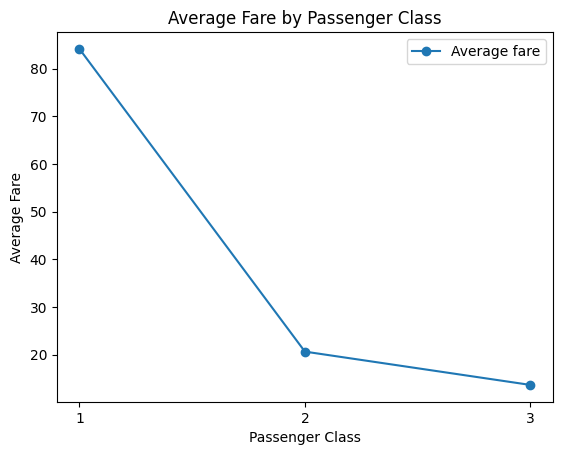

In [7]:
# Average fare for each passenger class
avg_fare = df.groupby("Pclass")["Fare"].mean()
print(avg_fare)

# Draw the line plot
plt.plot(avg_fare.index, avg_fare.values, marker="o", label="Average fare")
plt.title("Average Fare by Passenger Class")
plt.xlabel("Passenger Class")
plt.ylabel("Average Fare")
plt.xticks([1, 2, 3])
plt.legend()
plt.show()

**Interpretation:** First class paid the highest average fare (about 84). Second class paid about 21 and third class about 14. The biggest drop is between first and second class.

---
## Problem 3 - Scatter Plot: Age and Fare

Each point is one passenger. Passengers with a missing age are not shown.

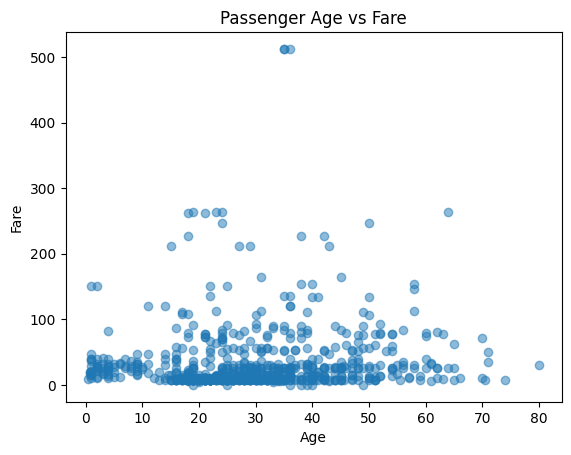

Correlation: 0.09606669176903894


In [8]:
# Draw the scatter plot
plt.scatter(df["Age"], df["Fare"], alpha=0.5)
plt.title("Passenger Age vs Fare")
plt.xlabel("Age")
plt.ylabel("Fare")
plt.show()

# Check how strong the relationship is
print("Correlation:", df["Age"].corr(df["Fare"]))

**Interpretation:** Most passengers paid a low fare. The correlation is about 0.10, so age and fare have a very weak relationship. A few points above 500 are outliers.

---
## Problem 4 - Bar Chart: Male and Female Passengers

Sex
male      577
female    314
Name: count, dtype: int64


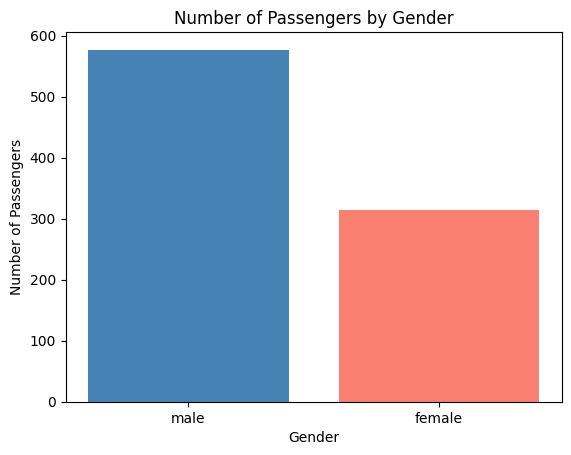

In [9]:
# Count male and female passengers
gender_count = df["Sex"].value_counts()
print(gender_count)

# Draw the bar chart
plt.bar(gender_count.index, gender_count.values, color=["steelblue", "salmon"])
plt.title("Number of Passengers by Gender")
plt.xlabel("Gender")
plt.ylabel("Number of Passengers")
plt.show()

**Interpretation:** There were 577 male and 314 female passengers, so there were many more males than females.

---
## Problem 5 - Histogram: Passenger Ages

We remove the missing ages and use 16 bins, so each bin covers about 5 years.

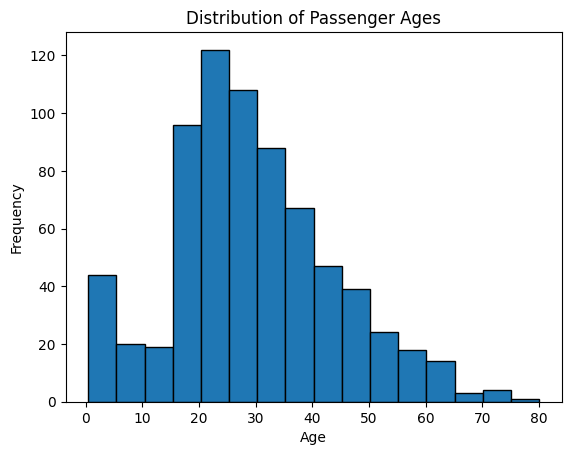

In [10]:
# Draw the histogram of age
plt.hist(df["Age"].dropna(), bins=16, edgecolor="black")
plt.title("Distribution of Passenger Ages")
plt.xlabel("Age")
plt.ylabel("Frequency")
plt.show()

**Interpretation:** Most passengers were young adults, mainly between 20 and 35 years old. The median age is 28. Very few passengers were older than 65. The 177 missing ages are not included.

---
## Problem 6 - Pie Chart: Survival

In the data, `0` means did not survive and `1` means survived.

Survived
0    549
1    342
Name: count, dtype: int64


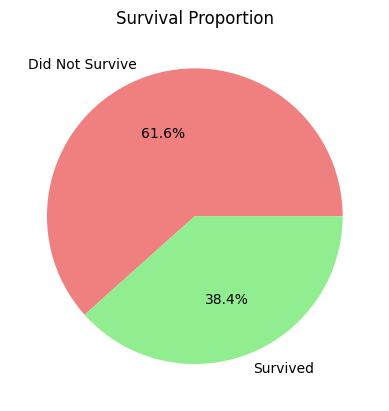

In [11]:
# Count survivors and non-survivors (0 first, then 1)
survival_count = df["Survived"].value_counts().sort_index()
print(survival_count)

# Draw the pie chart
labels = ["Did Not Survive", "Survived"]
plt.pie(survival_count, labels=labels, autopct="%1.1f%%", colors=["lightcoral", "lightgreen"])
plt.title("Survival Proportion")
plt.show()

**Interpretation:** About 61.6% of passengers did not survive and only 38.4% survived.

---
## Problem 7 - Two Subplots: Age and Passenger Class

Pclass
1    216
2    184
3    491
Name: count, dtype: int64


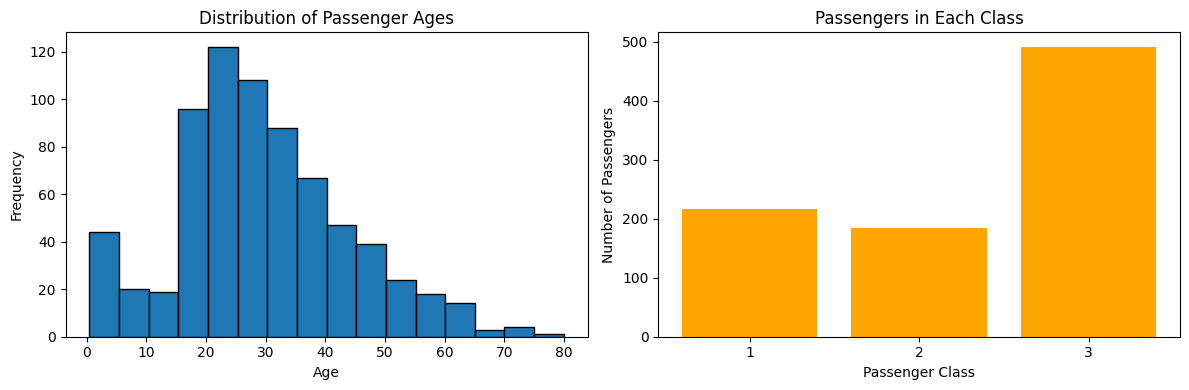

In [12]:
# Count passengers in each class
class_count = df["Pclass"].value_counts().sort_index()
print(class_count)

# One row and two columns
fig, ax = plt.subplots(1, 2, figsize=(12, 4))

# Histogram of age
ax[0].hist(df["Age"].dropna(), bins=16, edgecolor="black")
ax[0].set_title("Distribution of Passenger Ages")
ax[0].set_xlabel("Age")
ax[0].set_ylabel("Frequency")

# Bar chart of passenger class
ax[1].bar(class_count.index, class_count.values, color="orange")
ax[1].set_title("Passengers in Each Class")
ax[1].set_xlabel("Passenger Class")
ax[1].set_ylabel("Number of Passengers")
ax[1].set_xticks([1, 2, 3])

plt.tight_layout()
plt.show()

**Interpretation:** The age chart shows that most passengers were young adults. Third class had the most passengers (491), followed by first class (216) and second class (184).

---
## Problem 8 - Three Subplots: Gender, Fare and Survival

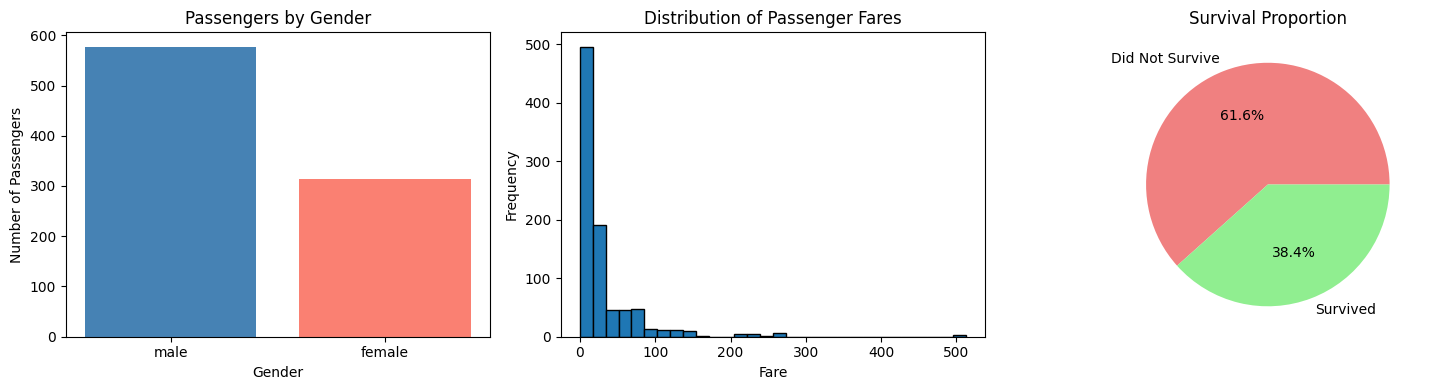

In [13]:
# One row and three columns
fig, ax = plt.subplots(1, 3, figsize=(15, 4))

# 1. Bar chart of gender
ax[0].bar(gender_count.index, gender_count.values, color=["steelblue", "salmon"])
ax[0].set_title("Passengers by Gender")
ax[0].set_xlabel("Gender")
ax[0].set_ylabel("Number of Passengers")

# 2. Histogram of fare
ax[1].hist(df["Fare"], bins=30, edgecolor="black")
ax[1].set_title("Distribution of Passenger Fares")
ax[1].set_xlabel("Fare")
ax[1].set_ylabel("Frequency")

# 3. Pie chart of survival
ax[2].pie(survival_count, labels=labels, autopct="%1.1f%%", colors=["lightcoral", "lightgreen"])
ax[2].set_title("Survival Proportion")

plt.tight_layout()
plt.show()

**Interpretation:**

- There were more male passengers (577) than female passengers (314).
- The fare histogram is right-skewed. About 82% of passengers paid less than 50, and only a few paid very high fares.
- More passengers died (61.6%) than survived (38.4%).

---
## Conclusion

- A **line plot** showed how the average fare changes from class to class.
- A **scatter plot** compared two numerical columns.
- **Bar charts** compared categories.
- **Histograms** showed the distribution of numbers.
- **Pie charts** showed proportions.
- **Subplots** showed many charts in one figure.